# Assignment 1 — Data Exploration and Cleaning: Truths

This notebook explores and cleans `truths.csv`, identifying data quality issues and applying validated corrections.

The final dataset will be used for integration with the other Truth Social datasets and subsequent assignments.

In [2]:
from pathlib import Path
import sys

MODULE_ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "text_features.py").is_file()
    ),
    None
)

if MODULE_ROOT is None:
    raise FileNotFoundError(
        "Place text_features.py in the repository root "
        "and start the notebook from the repository."
    )

if str(MODULE_ROOT) not in sys.path:
    sys.path.insert(0, str(MODULE_ROOT))

from text_features import extract_text_features, TEXT_FEATURE_COLUMNS
import pandas as pd

DATA_DIR = Path("../../ProjectData")

DATA_PATH = DATA_DIR / "truths.csv"

# Load all columns as strings to preserve the original values
df_raw = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    dtype="string",
    keep_default_na=False
)

print("Rows:", len(df_raw))
print("Columns:", df_raw.shape[1])

display(df_raw.head())


Rows: 1051149
Columns: 13


,id,timestamp,time_scraped,is_retruth,is_reply,author,like_count,retruth_count,reply_count,text,external_id,url,truth_retruthed
0,703265,2022-05-14 00:00:00,2022-11-01 15:48:16.829245,t,f,2247.0,0,0,0,Q+ BE READY ANONS - PUBLIC AWAKENING COMING - ...,108351978111014587,https://truthsocial.com/@jweimer39/posts/10835...,1043583.0
1,807614,2022-03-27 00:00:00,2022-11-23 10:54:36.865046,t,f,20054.0,0,0,0,Enough is enough! RETRUTH,108040697775316106,https://truthsocial.com/@CeceBloomwood/posts/1...,988567.0
2,807615,2022-03-29 00:00:00,2022-11-23 10:55:11.613249,t,f,20054.0,0,0,0,https://justthenews.com/politics-policy/all-th...,108040478595657472,https://truthsocial.com/@CeceBloomwood/posts/1...,1002825.0
3,807618,2022-03-29 00:00:00,2022-11-23 10:56:29.134825,t,f,20054.0,0,0,0,https://t.me/realx22report/6729,108040420546204424,https://truthsocial.com/@CeceBloomwood/posts/1...,989757.0
4,807619,2022-03-29 00:00:00,2022-11-23 10:57:20.028953,f,t,20054.0,0,0,0,@CeceBloomwood,108040224733670356,https://truthsocial.com/@CeceBloomwood/posts/1...,-1.0


## 1. Dataset Overview

We first examine the dataset structure, column names, data types, and missing values before applying any cleaning operations.

In [4]:

print("Dataset shape:", df_raw.shape)

display(
    pd.DataFrame({
        "Column": df_raw.columns,
        "Data type": df_raw.dtypes.astype(str).values
    })
)

display(df_raw.head(5))


Dataset shape: (1051149, 13)


,Column,Data type
0,id,string
1,timestamp,string
2,time_scraped,string
3,is_retruth,string
4,is_reply,string
5,author,string
6,like_count,string
7,retruth_count,string
8,reply_count,string
9,text,string


,id,timestamp,time_scraped,is_retruth,is_reply,author,like_count,retruth_count,reply_count,text,external_id,url,truth_retruthed
0,703265,2022-05-14 00:00:00,2022-11-01 15:48:16.829245,t,f,2247.0,0,0,0,Q+ BE READY ANONS - PUBLIC AWAKENING COMING - ...,108351978111014587,https://truthsocial.com/@jweimer39/posts/10835...,1043583.0
1,807614,2022-03-27 00:00:00,2022-11-23 10:54:36.865046,t,f,20054.0,0,0,0,Enough is enough! RETRUTH,108040697775316106,https://truthsocial.com/@CeceBloomwood/posts/1...,988567.0
2,807615,2022-03-29 00:00:00,2022-11-23 10:55:11.613249,t,f,20054.0,0,0,0,https://justthenews.com/politics-policy/all-th...,108040478595657472,https://truthsocial.com/@CeceBloomwood/posts/1...,1002825.0
3,807618,2022-03-29 00:00:00,2022-11-23 10:56:29.134825,t,f,20054.0,0,0,0,https://t.me/realx22report/6729,108040420546204424,https://truthsocial.com/@CeceBloomwood/posts/1...,989757.0
4,807619,2022-03-29 00:00:00,2022-11-23 10:57:20.028953,f,t,20054.0,0,0,0,@CeceBloomwood,108040224733670356,https://truthsocial.com/@CeceBloomwood/posts/1...,-1.0


In [5]:

# Count empty strings and common missing-value markers
missing_markers = ["", "NA", "N/A", "NULL", "NONE", "NAN"]

missing = pd.DataFrame({
    "Missing": [
        df_raw[col].str.strip().str.upper().isin(missing_markers).sum()
        for col in df_raw.columns
    ]
}, index=df_raw.columns)

missing["Percentage"] = (
    missing["Missing"] / len(df_raw) * 100
).round(2)

display(missing)


,Missing,Percentage
id,0,0.00
timestamp,0,0.00
time_scraped,0,0.00
is_retruth,0,0.00
is_reply,0,0.00
author,237,0.02
like_count,0,0.00
retruth_count,0,0.00
reply_count,0,0.00
text,322,0.03


## 2. Duplicate Detection

We identify exact duplicate rows and duplicated post IDs.

Exact duplicates can be safely removed, while records sharing the same ID but containing different information require further investigation.

In [7]:

# Count exact duplicates
exact_duplicates = df_raw.duplicated().sum()

# Remove exact copies to identify conflicting IDs
distinct_rows = df_raw.drop_duplicates()

id_counts = distinct_rows["id"].value_counts()
conflicting_ids = id_counts[id_counts > 1].index

print("Exact duplicates:", exact_duplicates)
print("IDs with conflicting records:", len(conflicting_ids))

# Inspect conflicting records
conflicting_records = distinct_rows[
    distinct_rows["id"].isin(conflicting_ids)
]

display(
    conflicting_records[
        ["id", "external_id", "url", "truth_retruthed"]
    ]
)


Exact duplicates: 12324
IDs with conflicting records: 4


,id,external_id,url,truth_retruthed
67135,777869,107949589049761167,https://truthsocial.com/@southerngrl1980/posts...,1056992.0
166203,951819,108476455287288244,https://truthsocial.com/@jrb1954/posts/1084764...,1012958.0
622080,537119,107927162142169655,https://truthsocial.com/@schivelbeinalan/posts...,1039015.0
740843,683069,108476740611883979,https://truthsocial.com/@TexasMAGAStorm/posts/...,1060937.0
763742,951819,109110899592280359,https://truthsocial.com/@realDonaldTrump/posts...,-1.0
766959,537119,107949054643865963,https://truthsocial.com/@JackPosobiec/posts/10...,-1.0
768217,777869,108301142290305867,https://truthsocial.com/@JackPosobiec/posts/10...,-1.0
772514,683069,109110717273944816,https://truthsocial.com/@realDonaldTrump/posts...,-1.0


In [8]:

# Create the working dataset
df_clean = df_raw.drop_duplicates().reset_index(drop=True).copy()

print("Original rows:", len(df_raw))
print("Removed duplicates:", len(df_raw) - len(df_clean))
print("Remaining rows:", len(df_clean))

assert df_clean.duplicated().sum() == 0


Original rows: 1051149
Removed duplicates: 12324
Remaining rows: 1038825


## 3. Data Type Conversion

The dataset was initially loaded as strings to preserve its original values.

We now convert identifiers, timestamps, boolean flags, and engagement metrics into appropriate data types.

In [10]:

# Convert identifiers
for col in ["id", "author"]:
    df_clean[col] = pd.to_numeric(
        df_clean[col].replace("", pd.NA),
        errors="raise"
    ).astype("Int64")

# Convert timestamps
for col in ["timestamp", "time_scraped"]:
    df_clean[col] = pd.to_datetime(
        df_clean[col],
        format="ISO8601",
        errors="raise"
    )

# Convert boolean flags
for col in ["is_retruth", "is_reply"]:
    df_clean[col] = (
        df_clean[col]
        .map({"t": True, "f": False})
        .astype("boolean")
    )

# Convert engagement metrics
engagement_cols = ["like_count", "retruth_count", "reply_count"]

for col in engagement_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="raise"
    ).astype("Int64")

display(df_clean.dtypes)


id                          Int64
timestamp          datetime64[ns]
time_scraped       datetime64[ns]
is_retruth                boolean
is_reply                  boolean
author                      Int64
like_count                  Int64
retruth_count               Int64
reply_count                 Int64
text               string[python]
external_id        string[python]
url                string[python]
truth_retruthed    string[python]
dtype: object

In [11]:

# Check missing values after type conversion
display(df_clean.isna().sum())

# Check boolean values
for col in ["is_retruth", "is_reply"]:
    print(f"\n{col}")
    print(df_clean[col].value_counts(dropna=False))

# Verify dataset size
assert len(df_clean) == len(df_raw) - exact_duplicates


id                   0
timestamp            0
time_scraped         0
is_retruth           0
is_reply             0
author             145
like_count           0
retruth_count        0
reply_count          0
text                 0
external_id          0
url                  0
truth_retruthed      0
dtype: int64


is_retruth
is_retruth
False    792743
True     246082
Name: count, dtype: Int64

is_reply
is_reply
False    751685
True     287140
Name: count, dtype: Int64


## 4. Missing Values and Author Recovery

After removing duplicates, 145 posts have a missing `author` value.

We attempt to recover these IDs by matching usernames with existing records in `truths.csv` and, subsequently, with `users.xml`.

Only unambiguous username-to-author mappings are used.

In [13]:

# Extract usernames from post URLs
url_username = df_clean["url"].str.extract(
    r"(?i)truthsocial\.com/@([^/]+)/posts/",
    expand=False
).str.lower()

# Identify usernames stored in external_id
external_username = df_clean["external_id"].str.lower().where(
    df_clean["external_id"].str.fullmatch(
        r"(?i)[a-z0-9_]*[a-z_][a-z0-9_]*",
        na=False
    )
)

# Build username-author mappings from known records
known = pd.DataFrame({
    "username": url_username,
    "author": df_clean["author"]
}).dropna()

valid = known.groupby("username")["author"].nunique()
valid = valid[valid == 1].index

author_map = (
    known[known["username"].isin(valid)]
    .groupby("username")["author"]
    .first()
)

# Recover authors using available usernames
from_url = url_username.map(author_map)
from_external = external_username.map(author_map)

conflicts = (
    from_url.notna() & from_external.notna()
    & from_url.ne(from_external).fillna(False)
)

candidate = from_url.combine_first(from_external)
missing = df_clean["author"].isna()
recovered_internal = missing & candidate.notna() & ~conflicts

df_clean.loc[recovered_internal, "author"] = candidate[recovered_internal]

print("Recovered internally:", recovered_internal.sum())
print("Missing authors remaining:", df_clean["author"].isna().sum())


Recovered internally: 58
Missing authors remaining: 87


### 4.1 Cross-Dataset Recovery

The remaining missing authors are recovered using `users.xml`, which contains user IDs and usernames.

Matching is performed on normalized usernames, excluding ambiguous mappings.

In [15]:

import xml.etree.ElementTree as ET

USERS_PATH = DATA_DIR / "users.xml"

root = ET.parse(USERS_PATH).getroot()

# Extract user IDs and usernames
users = pd.DataFrame([
    {
        "id_user": row.findtext("id_user"),
        "username": row.findtext("username")
    }
    for row in root.findall("row")
])

users["id_user"] = pd.to_numeric(
    users["id_user"], errors="coerce"
).astype("Int64")

users["username"] = users["username"].str.strip().str.lower()
users = users.dropna(subset=["id_user", "username"])
users = users[users["username"] != ""]

# Keep only unambiguous username mappings
valid = users.groupby("username")["id_user"].nunique()
valid = valid[valid == 1].index

users_map = (
    users[users["username"].isin(valid)]
    .groupby("username")["id_user"]
    .first()
)

# Recover remaining authors
username = url_username.combine_first(external_username)
candidate = username.map(users_map)

missing = df_clean["author"].isna()
recovered_external = missing & candidate.notna()

df_clean.loc[recovered_external, "author"] = candidate[recovered_external]

print("Recovered from users.xml:", recovered_external.sum())
print("Missing authors remaining:", df_clean["author"].isna().sum())


Recovered from users.xml: 87
Missing authors remaining: 0


In [16]:

print("AUTHOR RECOVERY SUMMARY")
print("-----------------------")
print("Initially missing:", 145)
print("Recovered internally:", recovered_internal.sum())
print("Recovered from users.xml:", recovered_external.sum())
print("Remaining missing:", df_clean["author"].isna().sum())

# Verify that recovered authors match the users dataset
recovered = recovered_internal | recovered_external

expected_author = username.map(users_map)

matches = (
    df_clean.loc[recovered, "author"]
    .eq(expected_author.loc[recovered])
)

print("Validated against users.xml:", matches.sum())

assert df_clean["author"].isna().sum() == 0
assert matches.fillna(False).all()


AUTHOR RECOVERY SUMMARY
-----------------------
Initially missing: 145
Recovered internally: 58
Recovered from users.xml: 87
Remaining missing: 0
Validated against users.xml: 145


## 5. Text Quality and Cleaning

We identify missing, malformed, and potentially unusable post texts.

We also investigate recovery opportunities using other records and datasets, while preserving the original content.

In [18]:

# Identify empty and malformed texts
text = df_clean["text"].str.strip()

empty_text = text.isin(["", "None", "NULL", "N/A", "NaN"])
malformed_text = text.eq("<")

problematic_text = empty_text | malformed_text

print("Empty or placeholder texts:", empty_text.sum())
print("Malformed texts:", malformed_text.sum())
print("Total problematic texts:", problematic_text.sum())

display(
    df_clean.loc[
        problematic_text,
        ["id", "text", "is_retruth", "is_reply"]
    ].head(10)
)


Empty or placeholder texts: 178
Malformed texts: 5423
Total problematic texts: 5601


,id,text,is_retruth,is_reply
1167,807655,,True,False
1193,704620,<,True,False
1227,704633,<,True,False
1244,804752,,False,False
1263,807647,,True,False
10026,713325,<,True,False
10045,713386,<,True,False
10052,805569,,True,True
15831,720084,<,True,False
15842,720115,<,True,False


In [19]:

# Build a mapping from IDs with valid texts
valid_text = df_clean.loc[
    ~problematic_text, ["id", "text"]
]

text_counts = valid_text.groupby("id")["text"].nunique()
unique_ids = text_counts[text_counts == 1].index

text_map = (
    valid_text[valid_text["id"].isin(unique_ids)]
    .groupby("id")["text"]
    .first()
)

# Find recoverable texts
text_candidate = df_clean["id"].map(text_map)
recoverable_text = problematic_text & text_candidate.notna()

print("Recoverable internally:", recoverable_text.sum())
print("Still unresolved:", (problematic_text & ~recoverable_text).sum())


Recoverable internally: 0
Still unresolved: 5601


In [20]:

import arff
import re

ARFF_PATH = DATA_DIR / "additional_truths.arff"

with open(ARFF_PATH, encoding="utf-8-sig") as file:
    content = file.read()

# Handle unsupported escape sequences
content = re.sub(r"(?<!\\)\\x", r"\\\\x", content)

arff_data = arff.loads(content)
columns = [col[0] for col in arff_data["attributes"]]

additional_df = pd.DataFrame(arff_data["data"], columns=columns)

# Match external post identifiers
post_ids = df_clean["url"].str.extract(
    r"(?i)truthsocial\.com/@[^/]+/posts/(\d+)",
    expand=False
)

arff_ids = additional_df["external_id"].astype("string").str.strip()

matches = set(post_ids[problematic_text].dropna()) & set(arff_ids.dropna())

print("Matching post IDs in ARFF:", len(matches))


Matching post IDs in ARFF: 1


In [21]:

MEDIA_PATH = DATA_DIR / "media.json"

media_df = pd.read_json(MEDIA_PATH)

media_ids = pd.to_numeric(
    media_df["truth_id"], errors="coerce"
).dropna()

df_clean["has_media"] = df_clean["id"].isin(media_ids)

print("Problematic texts:", problematic_text.sum())
print("With media:", (problematic_text & df_clean["has_media"]).sum())
print("Without media:", (problematic_text & ~df_clean["has_media"]).sum())


Problematic texts: 5601
With media: 1544
Without media: 4057


In [22]:

import html

# Create a clean copy of the text column
df_clean["text_clean"] = df_clean["text"].copy()

# Decode HTML entities only where necessary
has_entities = df_clean["text_clean"].str.contains(
    r"&(?:#\d+|#x[0-9a-fA-F]+|[a-zA-Z]+);",
    regex=True,
    na=False
)

df_clean.loc[has_entities, "text_clean"] = (
    df_clean.loc[has_entities, "text_clean"]
    .astype("object")
    .map(html.unescape)
    .values
)

# Mark problematic texts as missing
df_clean.loc[problematic_text, "text_clean"] = pd.NA

# Classify text quality
df_clean["text_quality_status"] = "valid"
df_clean.loc[empty_text, "text_quality_status"] = "empty"
df_clean.loc[malformed_text, "text_quality_status"] = "malformed"

display(df_clean["text_quality_status"].value_counts())

print("Usable texts:", df_clean["text_clean"].notna().sum())
print("Unusable texts:", df_clean["text_clean"].isna().sum())


text_quality_status
valid        1033224
malformed       5423
empty            178
Name: count, dtype: int64

Usable texts: 1033224
Unusable texts: 5601


In [23]:

assert df_clean.loc[problematic_text, "text_clean"].isna().all()
assert df_clean.loc[~problematic_text, "text_clean"].notna().all()

assert (
    df_clean["text_clean"].isna().sum()
    == problematic_text.sum()
)

print("Text quality validation passed.")


Text quality validation passed.


## 6. Timestamp Quality and Temporal Consistency

We examine publication and scraping timestamps to identify invalid dates, limited time precision, and chronological inconsistencies.

Ambiguous timestamps are flagged rather than artificially corrected.

In [25]:

# Check timestamp ranges and missing values
display(pd.DataFrame({
    "Missing": df_clean[["timestamp", "time_scraped"]].isna().sum(),
    "Earliest": df_clean[["timestamp", "time_scraped"]].min(),
    "Latest": df_clean[["timestamp", "time_scraped"]].max()
}))

# Identify timestamps recorded at midnight
midnight_publication = (
    df_clean["timestamp"]
    .eq(df_clean["timestamp"].dt.normalize())
)

midnight_scraping = (
    df_clean["time_scraped"]
    .eq(df_clean["time_scraped"].dt.normalize())
)

print("Publication timestamps at midnight:", midnight_publication.sum())
print("Scraping timestamps at midnight:", midnight_scraping.sum())


,Missing,Earliest,Latest
timestamp,0,2022-02-07 23:31:00.000000,2024-10-29 21:24:00
time_scraped,0,2022-09-14 17:27:42.677694,2024-10-29 00:00:00


Publication timestamps at midnight: 219685
Scraping timestamps at midnight: 277911


In [26]:

# Posts apparently published after scraping
inconsistent = df_clean["timestamp"] > df_clean["time_scraped"]

# Check whether the inconsistency occurs on the same day
same_day = (
    df_clean["timestamp"].dt.normalize()
    == df_clean["time_scraped"].dt.normalize()
)

# Separate ambiguous timestamps from actual inconsistencies
midnight_ambiguity = inconsistent & same_day & midnight_scraping
chronological_error = inconsistent & ~midnight_ambiguity

print("Publication after scraping:", inconsistent.sum())
print("Same-day midnight ambiguity:", midnight_ambiguity.sum())
print("Other chronological inconsistencies:", chronological_error.sum())

display(
    df_clean.loc[
        inconsistent,
        ["id", "timestamp", "time_scraped"]
    ].head(10)
)


Publication after scraping: 62239
Same-day midnight ambiguity: 62239
Other chronological inconsistencies: 0


,id,timestamp,time_scraped
760914,1060960,2024-06-14 21:06:00,2024-06-14
760915,1060985,2024-06-14 20:53:00,2024-06-14
760916,1061003,2024-06-14 20:40:00,2024-06-14
760917,1061013,2024-06-14 20:32:00,2024-06-14
760918,1061017,2024-06-14 20:28:00,2024-06-14
760919,1061018,2024-06-14 20:28:00,2024-06-14
760920,1061020,2024-06-14 20:28:00,2024-06-14
760921,1061023,2024-06-14 20:27:00,2024-06-14
760922,1061025,2024-06-14 20:27:00,2024-06-14
760923,1061027,2024-06-14 20:25:00,2024-06-14


In [27]:

df_clean["temporal_quality_status"] = "valid"

df_clean.loc[
    midnight_ambiguity,
    "temporal_quality_status"
] = "midnight_ambiguity"

df_clean.loc[
    chronological_error,
    "temporal_quality_status"
] = "chronological_inconsistency"

df_clean.loc[
    df_clean["timestamp"].isna() | df_clean["time_scraped"].isna(),
    "temporal_quality_status"
] = "missing"

display(df_clean["temporal_quality_status"].value_counts())


temporal_quality_status
valid                 976586
midnight_ambiguity     62239
Name: count, dtype: int64

In [28]:

# Identify date-only values in the original dataset
date_only = df_raw["timestamp"].str.strip().str.fullmatch(
    r"\d{4}-\d{2}-\d{2}",
    na=False
)

print("Original date-only timestamps:", date_only.sum())
print("Original midnight timestamps:", (
    df_raw["timestamp"].str.contains(
        r"[ T]00:00:00(?:\.0+)?$",
        regex=True,
        na=False
    )
).sum())

print("Midnight timestamps after cleaning:", midnight_publication.sum())


Original date-only timestamps: 918
Original midnight timestamps: 224963
Midnight timestamps after cleaning: 219685


In [29]:

# Identify records with date-only publication timestamps
date_only_ids = df_raw.loc[date_only, "id"]

df_clean["timestamp_date_only"] = (
    df_clean["id"].astype("string").isin(date_only_ids)
)

print("Date-only timestamps preserved:",
      df_clean["timestamp_date_only"].sum())


Date-only timestamps preserved: 918


## 7. Engagement Metrics and Outlier Detection

We analyze likes, retruths, and replies to identify invalid values, unusual distributions, and potential outliers.

High engagement values are not automatically considered errors, as viral posts can legitimately receive unusually large numbers of interactions.

In [31]:

engagement_cols = ["like_count", "retruth_count", "reply_count"]

# Descriptive statistics
display(
    df_clean[engagement_cols].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    ).round(2)
)

# Check invalid negative values
negative_counts = (df_clean[engagement_cols] < 0).sum()

print("Negative values:")
display(negative_counts)


,like_count,retruth_count,reply_count
count,1038825.0,1038825.0,1038825.0
mean,24.45,9.42,3.19
std,243.45,91.16,35.8
min,0.0,0.0,0.0
50%,1.0,0.0,0.0
90%,15.0,7.0,3.0
95%,61.0,25.0,8.0
99%,402.52,158.0,55.0
max,31340.0,12183.0,7137.0


Negative values:


like_count       0
retruth_count    0
reply_count      0
dtype: Int64

In [32]:

# Count posts with zero engagement
zero_counts = (df_clean[engagement_cols] == 0).sum()

zero_percentage = (
    zero_counts / len(df_clean) * 100
).round(2)

display(pd.DataFrame({
    "Zero values": zero_counts,
    "Percentage": zero_percentage
}))

# Posts with no recorded engagement
no_engagement = (df_clean[engagement_cols] == 0).all(axis=1)

print("Posts with zero engagement:", no_engagement.sum())
print("Percentage:", round(no_engagement.mean() * 100, 2))


,Zero values,Percentage
like_count,373140,35.92
retruth_count,730778,70.35
reply_count,561995,54.1


Posts with zero engagement: 373024
Percentage: 35.91


### 7.1 Outlier Detection

We use the Interquartile Range (IQR) method to identify unusually high engagement values.

These outliers are analyzed but not removed, since they may represent genuine viral activity.

In [34]:

outlier_summary = []

for col in engagement_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)

    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr

    outliers = (df_clean[col] > upper_bound).sum()

    outlier_summary.append({
        "Metric": col,
        "Upper bound": upper_bound,
        "Outliers": outliers,
        "Percentage": round(outliers / len(df_clean) * 100, 2)
    })

display(pd.DataFrame(outlier_summary))


,Metric,Upper bound,Outliers,Percentage
0,like_count,7.5,150927,14.53
1,retruth_count,2.5,179083,17.24
2,reply_count,2.5,108201,10.42


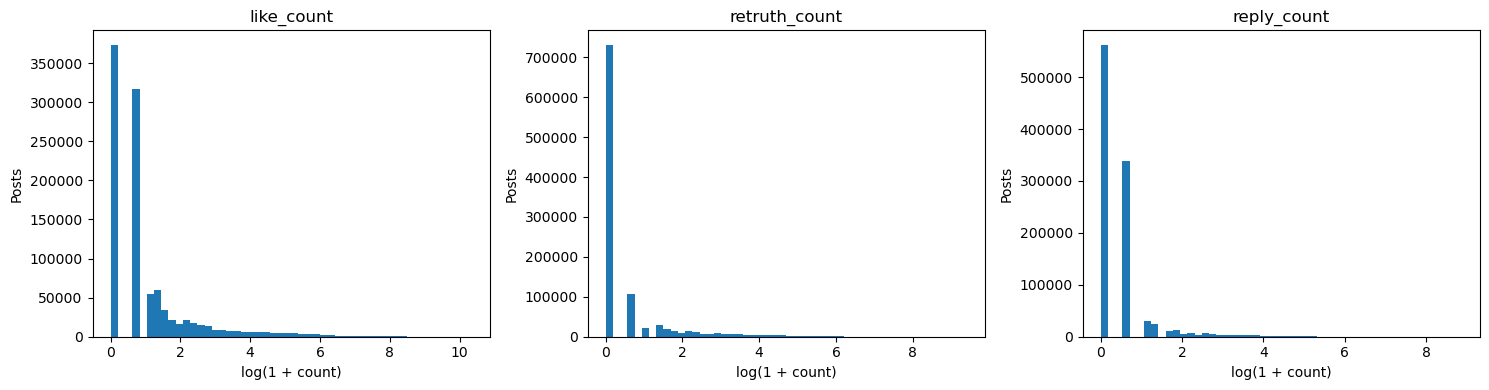

In [35]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, engagement_cols):
    values = np.log1p(df_clean[col].dropna().astype(float))

    ax.hist(values, bins=50)
    ax.set_title(col)
    ax.set_xlabel("log(1 + count)")
    ax.set_ylabel("Posts")

plt.tight_layout()
plt.show()


In [36]:

# Total recorded engagement
df_clean["total_engagement"] = df_clean[engagement_cols].sum(axis=1)

# Show the most engaged posts
display(
    df_clean.nlargest(10, "total_engagement")[
        ["id", "author", "timestamp",
         "like_count", "retruth_count",
         "reply_count", "total_engagement"]
    ]
)


,id,author,timestamp,like_count,retruth_count,reply_count,total_engagement
245702,69023,96,2022-04-28 17:29:00,31340,12183,7137,50660
291389,125307,2885,2022-04-28 17:29:00,31340,12183,7137,50660
295266,130407,2882,2022-04-28 17:29:00,31340,12183,7137,50660
486328,366255,5078,2022-04-28 17:29:00,31340,12183,7137,50660
486731,366931,8235,2022-04-28 17:29:00,31340,12183,7137,50660
525455,413805,8768,2022-04-28 17:29:00,31340,12183,7137,50660
534582,424756,9318,2022-04-28 17:29:00,31340,12183,7137,50660
605328,510621,10426,2022-04-28 17:29:00,31340,12183,7137,50660
44305,754447,19573,2022-02-14 00:00:00,22069,5862,4582,32513
454001,325285,6624,2022-02-14 10:54:00,22069,5862,4582,32513


In [37]:

# Inspect posts sharing the highest engagement values
top_engagement = df_clean["total_engagement"].max()

top_posts = df_clean[
    df_clean["total_engagement"] == top_engagement
]

display(
    top_posts[
        ["id", "author", "is_retruth",
         "truth_retruthed", "like_count",
         "retruth_count", "reply_count"]
    ]
)

print("Posts sharing maximum engagement:", len(top_posts))
print("Unique original posts:", top_posts["truth_retruthed"].nunique())


,id,author,is_retruth,truth_retruthed,like_count,retruth_count,reply_count
245702,69023,96,True,0.0,31340,12183,7137
291389,125307,2885,True,0.0,31340,12183,7137
295266,130407,2882,True,0.0,31340,12183,7137
486328,366255,5078,True,0.0,31340,12183,7137
486731,366931,8235,True,0.0,31340,12183,7137
525455,413805,8768,True,0.0,31340,12183,7137
534582,424756,9318,True,0.0,31340,12183,7137
605328,510621,10426,True,0.0,31340,12183,7137


Posts sharing maximum engagement: 8
Unique original posts: 1


## 8. Identifier Consistency

We investigate duplicated post IDs containing conflicting information.

Conflicting records are validated using author information from `users.xml`. Only records with verified author-username relationships are retained.

We also examine retruth references and their consistency with the main dataset.

In [39]:

# Find records sharing the same ID
conflicts = df_clean[
    df_clean["id"].duplicated(keep=False)
].copy()

# Extract usernames from URLs
conflicts["username"] = conflicts["url"].str.extract(
    r"(?i)truthsocial\.com/@([^/]+)/posts/",
    expand=False
).str.lower()

# Validate authors using users.xml
conflicts["expected_author"] = conflicts["username"].map(users_map)

conflicts["author_match"] = (
    conflicts["author"] == conflicts["expected_author"]
).fillna(False)

display(
    conflicts[
        ["id", "author", "username",
         "expected_author", "author_match"]
    ].sort_values("id")
)

print("Conflicting IDs:", conflicts["id"].nunique())
print("Validated records:", conflicts["author_match"].sum())


,id,author,username,expected_author,author_match
622080,537119,10925,schivelbeinalan,10925,True
760770,537119,10925,jackposobiec,143,False
740843,683069,2780,texasmagastorm,2780,True
760913,683069,2780,realdonaldtrump,27,False
67135,777869,19822,southerngrl1980,19822,True
760771,777869,19822,jackposobiec,143,False
166203,951819,21790,jrb1954,21790,True
760769,951819,21790,realdonaldtrump,27,False


Conflicting IDs: 4
Validated records: 4


In [40]:

# Ensure each conflicting ID has one valid version
valid_versions = conflicts.groupby("id")["author_match"].sum()

assert (valid_versions == 1).all()

# Identify incorrect versions
invalid_indices = conflicts.index[
    ~conflicts["author_match"]
]

# Preserve excluded records for inspection
discarded_conflicts = df_clean.loc[invalid_indices].copy()

# Remove incorrect records
df_clean = df_clean.drop(index=invalid_indices).reset_index(drop=True)

print("Removed conflicting records:", len(discarded_conflicts))
print("Remaining records:", len(df_clean))
print("Duplicated IDs:", df_clean["id"].duplicated().sum())

assert df_clean["id"].is_unique


Removed conflicting records: 4
Remaining records: 1038821
Duplicated IDs: 0


### 8.1 Retruth Reference Cleaning

The `truth_retruthed` column contains references to original posts, but also missing values and sentinel values such as `0` and `-1`.

We normalize the references and check whether the referenced posts exist in the dataset.

Missing references are preserved as missing values rather than replaced with invented identifiers.

In [42]:

# Convert retruth references to numeric values
references = pd.to_numeric(
    df_clean["truth_retruthed"],
    errors="coerce"
).astype("Int64")

# Examine invalid and sentinel values
print("Empty or non-numeric references:", references.isna().sum())
print("Zero references:", (references == 0).sum())
print("Minus one references:", (references == -1).sum())

# Keep only positive identifiers
df_clean["truth_retruthed_clean"] = references.where(references > 0)

print(
    "Missing references after cleaning:",
    df_clean["truth_retruthed_clean"].isna().sum()
)


Empty or non-numeric references: 277911
Zero references: 16182
Minus one references: 505472
Missing references after cleaning: 799565


In [43]:

# Check whether referenced posts exist
is_retruth = df_clean["is_retruth"].fillna(False)
reference = df_clean["truth_retruthed_clean"]

target_exists = reference.isin(df_clean["id"])
self_reference = reference.eq(df_clean["id"]).fillna(False)

# Classify references
df_clean["retruthed_reference_status"] = "not_retruth"

df_clean.loc[
    is_retruth & reference.isna(),
    "retruthed_reference_status"
] = "missing_reference"

df_clean.loc[
    is_retruth & reference.notna() & ~target_exists,
    "retruthed_reference_status"
] = "target_absent"

df_clean.loc[
    is_retruth & target_exists,
    "retruthed_reference_status"
] = "resolved"

df_clean.loc[
    is_retruth & self_reference,
    "retruthed_reference_status"
] = "self_reference"

df_clean.loc[
    ~is_retruth & reference.notna(),
    "retruthed_reference_status"
] = "inconsistent_non_retruth"

display(df_clean["retruthed_reference_status"].value_counts())


retruthed_reference_status
not_retruth                 792742
target_absent               153628
resolved                     79494
missing_reference             6823
self_reference                6133
inconsistent_non_retruth         1
Name: count, dtype: int64

### 8.2 External ID and URL Consistency

We examine the consistency between `external_id` and `url`.

Some records contain usernames in `external_id` and numeric post identifiers in `url`. We attempt to reconstruct these fields using validated author-username relationships from `users.xml`.

Original values are preserved, and unresolved anomalies are documented.

In [45]:

# Check external ID format
external_id = df_clean["external_id"].astype("string").str.strip()
url = df_clean["url"].astype("string").str.strip()

numeric_external = external_id.str.fullmatch(r"\d+", na=False).fillna(False)
numeric_url = url.str.fullmatch(r"\d+", na=False).fillna(False)

# Extract post IDs from standard URLs
url_post_id = url.str.extract(
    r"(?i)^https?://(?:www\.)?truthsocial\.com/@[^/]+/posts/(\d+)/?$",
    expand=False
)

valid_url = url_post_id.notna()

# Compare identifiers where possible
mismatch = (
    numeric_external
    & valid_url
    & external_id.ne(url_post_id).fillna(False)
)

print("Invalid external IDs:", (~numeric_external).sum())
print("Numeric-only URLs:", numeric_url.sum())
print("Other invalid URLs:", (~valid_url & ~numeric_url).sum())
print("External ID / URL mismatches:", mismatch.sum())

display(
    df_clean.loc[
        numeric_url,
        ["id", "author", "external_id", "url"]
    ].head(10)
)


Invalid external IDs: 17577
Numeric-only URLs: 17623
Other invalid URLs: 1
External ID / URL mismatches: 0


,id,author,external_id,url
1165,807653,20054,CeceBloomwood,107949547160373982
1166,807654,20054,CeceBloomwood,107945338731779453
1167,807655,20054,CeceBloomwood,107925568586381393
1168,807656,20054,CeceBloomwood,107914242452173533
1169,807657,20054,CeceBloomwood,107912178895243526
1170,704521,11225,PadingtonRose,108451075405955467
1171,704523,11225,PadingtonRose,108451037257647019
1172,704539,2335,Cmac67,108420053177728792
1173,704540,11225,PadingtonRose,108450814142383247
1174,704542,11225,PadingtonRose,108448432916302198


In [46]:

# Build an unambiguous author-to-username mapping
username_counts = users.groupby("id_user")["username"].nunique()
valid_authors = username_counts[username_counts == 1].index

author_map = (
    users[users["id_user"].isin(valid_authors)]
    .groupby("id_user")["username"]
    .first()
)

# Recover usernames using author IDs
username = df_clean["author"].map(author_map)

# Check that usernames stored in external_id are consistent
username_match = external_id.str.lower().eq(username).fillna(False)

# Select recoverable numeric URLs
recoverable = numeric_url & username.notna() & (
    numeric_external | username_match
)

print("Numeric URLs:", numeric_url.sum())
print("Recoverable URLs:", recoverable.sum())
print("Unresolved numeric URLs:", (numeric_url & ~recoverable).sum())


Numeric URLs: 17623
Recoverable URLs: 17622
Unresolved numeric URLs: 1


In [47]:

# Preserve original identifiers
df_clean["external_id_clean"] = external_id.copy()
df_clean["url_clean"] = url.copy()

# Recover numeric post IDs
df_clean.loc[recoverable, "external_id_clean"] = url[recoverable]

# Reconstruct standard URLs
df_clean.loc[recoverable, "url_clean"] = (
    "https://truthsocial.com/@"
    + username[recoverable]
    + "/posts/"
    + url[recoverable]
)

print("Reconstructed URLs:", recoverable.sum())

display(
    df_clean.loc[
        recoverable,
        ["id", "external_id_clean", "url_clean"]
    ].head(10)
)


Reconstructed URLs: 17622


,id,external_id_clean,url_clean
1165,807653,107949547160373982,https://truthsocial.com/@cecebloomwood/posts/1...
1166,807654,107945338731779453,https://truthsocial.com/@cecebloomwood/posts/1...
1167,807655,107925568586381393,https://truthsocial.com/@cecebloomwood/posts/1...
1168,807656,107914242452173533,https://truthsocial.com/@cecebloomwood/posts/1...
1169,807657,107912178895243526,https://truthsocial.com/@cecebloomwood/posts/1...
1170,704521,108451075405955467,https://truthsocial.com/@padingtonrose/posts/1...
1171,704523,108451037257647019,https://truthsocial.com/@padingtonrose/posts/1...
1172,704539,108420053177728792,https://truthsocial.com/@cmac67/posts/10842005...
1173,704540,108450814142383247,https://truthsocial.com/@padingtonrose/posts/1...
1174,704542,108448432916302198,https://truthsocial.com/@padingtonrose/posts/1...


In [48]:

# Validate cleaned identifiers
clean_external = df_clean["external_id_clean"].str.fullmatch(
    r"\d+", na=False
).fillna(False)

clean_url_id = df_clean["url_clean"].str.extract(
    r"(?i)^https?://(?:www\.)?truthsocial\.com/@[^/]+/posts/(\d+)/?$",
    expand=False
)

valid_clean_url = clean_url_id.notna()

# Check consistency between external IDs and URLs
mismatch = (
    clean_external
    & valid_clean_url
    & df_clean["external_id_clean"].ne(clean_url_id).fillna(False)
)

print("Valid external IDs:", clean_external.sum())
print("Valid URLs:", valid_clean_url.sum())
print("ID / URL mismatches:", mismatch.sum())

# Inspect unresolved records
unresolved = ~clean_external | ~valid_clean_url

print("Unresolved records:", unresolved.sum())

display(
    df_clean.loc[
        unresolved,
        ["id", "author", "external_id_clean", "url_clean"]
    ]
)


Valid external IDs: 1038819
Valid URLs: 1038819
ID / URL mismatches: 0
Unresolved records: 2


,id,author,external_id_clean,url_clean
134233,894769,21203,JackPosobiec,107947130681947614
519946,430702,9375,2022-03-07 07:16:00,2022-10-14 22:35:25.809822


In [49]:

# Recover the remaining numeric URL using its existing username
mask = df_clean["id"].eq(894769)

post_id = df_clean.loc[mask, "url_clean"].iloc[0]
username = df_clean.loc[mask, "external_id_clean"].iloc[0]

df_clean.loc[mask, "external_id_clean"] = post_id
df_clean.loc[mask, "url_clean"] = (
    f"https://truthsocial.com/@{username}/posts/{post_id}"
)

# Mark unrecoverable identifiers as missing
mask = df_clean["id"].eq(430702)

df_clean.loc[mask, ["external_id_clean", "url_clean"]] = pd.NA

print("Remaining invalid external IDs:",
      (~df_clean["external_id_clean"].str.fullmatch(
          r"\d+", na=False
      )).sum())

print("Remaining missing URLs:",
      df_clean["url_clean"].isna().sum())


Remaining invalid external IDs: 1
Remaining missing URLs: 1


In [50]:

# Check duplicated external identifiers
duplicated_external = df_clean[
    df_clean["external_id_clean"].notna()
    & df_clean["external_id_clean"].duplicated(keep=False)
]

print("Duplicated external IDs:",
      duplicated_external["external_id_clean"].nunique())

print("Records involved:", len(duplicated_external))

display(
    duplicated_external[
        ["id", "author", "external_id_clean", "url_clean"]
    ].head(10)
)


Duplicated external IDs: 50070
Records involved: 196014


,id,author,external_id_clean,url_clean
14021,718095,16675,108283824020818175,https://truthsocial.com/@aellis1224/posts/1082...
31300,819401,498,108875916520160231,https://truthsocial.com/@WallStreetApes/posts/...
38668,746778,166,108480157045931477,https://truthsocial.com/@KariLake/posts/108480...
38801,746740,166,108612109856515801,https://truthsocial.com/@KariLake/posts/108612...
41404,819590,498,108836175468554534,https://truthsocial.com/@WallStreetApes/posts/...
43421,752349,174,109113486460619152,https://truthsocial.com/@Kash/posts/1091134864...
80744,818451,498,109125020942159323,https://truthsocial.com/@wallstreetapes/posts/...
82190,818596,498,109073640809880891,https://truthsocial.com/@WallStreetApes/posts/...
82206,818567,498,109082523222879688,https://truthsocial.com/@WallStreetApes/posts/...
83499,851191,174,109113486460619152,https://truthsocial.com/@kash/posts/1091134864...


In [51]:

# Compare duplicated external IDs with retruth status
duplicated_mask = (
    df_clean["external_id_clean"].notna()
    & df_clean["external_id_clean"].duplicated(keep=False)
)

display(
    pd.crosstab(
        duplicated_mask,
        df_clean["is_retruth"],
        rownames=["Duplicated external ID"],
        colnames=["Is retruth"]
    )
)

# Check whether the same external ID is associated with different URLs
url_counts = (
    df_clean.loc[duplicated_mask]
    .groupby("external_id_clean")["url_clean"]
    .nunique()
)

print("External IDs with multiple URLs:", (url_counts > 1).sum())


Is retruth,False,True
Duplicated external ID,,
False,598209,244598
True,194534,1480


External IDs with multiple URLs: 1474


In [52]:
# Identify repeated, non-missing external IDs
ext = df_clean["external_id_clean"]

duplicate_mask = ext.notna() & ext.duplicated(keep=False)

external_counts = ext[ext.notna()].value_counts()
repeated_counts = external_counts[external_counts > 1]

print("Distinct repeated external IDs:", len(repeated_counts))
print("Rows involved:", duplicate_mask.sum())
print("Occurrences beyond the first:", (repeated_counts - 1).sum())

print("\nNumber of rows per repeated external ID:")
display(
    repeated_counts.describe(
        percentiles=[0.50, 0.90, 0.99]
    ).to_frame("Rows per external ID")
)

print("\nMost frequently repeated external IDs:")
display(repeated_counts.head(20).to_frame("Rows"))

Distinct repeated external IDs: 50070
Rows involved: 196014
Occurrences beyond the first: 145944

Number of rows per repeated external ID:


,Rows per external ID
count,50070.0
mean,3.914799
std,3.024993
min,2.0
50%,3.0
90%,7.0
99%,17.0
max,48.0



Most frequently repeated external IDs:


,Rows
external_id_clean,
111075428312143223,48
110294786824537508,41
112894089030815994,36
112871628839283471,35
112976651497722246,34
113002051073926943,33
112836162533176591,33
110640688915126411,32
112762809145492392,31


In [53]:
# Keep only the columns needed for the investigation
diagnostic_columns = [
    "id", "author", "external_id_clean", "url_clean",
    "text", "timestamp", "time_scraped",
    "is_retruth", "truth_retruthed_clean",
    "like_count", "retruth_count", "reply_count"
]

duplicate_details = df_clean.loc[
    duplicate_mask, diagnostic_columns
].copy()

groups = duplicate_details.groupby(
    "external_id_clean", sort=False
)

# Missing values count as a separate value:
# a populated value and a missing value are a difference.
variation_columns = [
    col for col in diagnostic_columns
    if col != "external_id_clean"
]

variation = groups[variation_columns].nunique(dropna=False)
variation.columns = ["n_" + col for col in variation.columns]

duplicate_summary = groups.size().to_frame("n_rows").join(variation)

variation_overview = pd.DataFrame({
    "Groups with differences": variation.gt(1).sum(),
    "Percentage of repeated ID groups": (
        variation.gt(1).mean() * 100
    ).round(2)
})

display(
    variation_overview.sort_values(
        "Groups with differences", ascending=False
    )
)

,Groups with differences,Percentage of repeated ID groups
n_id,50070,100.00
n_time_scraped,43684,87.25
n_like_count,15749,31.45
n_retruth_count,12625,25.21
n_reply_count,6335,12.65
n_text,2639,5.27
n_author,1525,3.05
n_url_clean,1474,2.94
n_is_retruth,1456,2.91
n_truth_retruthed_clean,1329,2.65


In [54]:
url_parts = duplicate_details["url_clean"].astype("string").str.extract(
    r"(?i)^https?://(?:www\.)?truthsocial\.com/"
    r"@(?P<url_username>[^/?#]+)/posts/(?P<url_post_id>\d+)/?$"
)

duplicate_details["url_username"] = (
    url_parts["url_username"].str.lower()
)
duplicate_details["url_post_id"] = url_parts["url_post_id"]

duplicate_details["canonical_url"] = (
    "https://truthsocial.com/@"
    + duplicate_details["url_username"]
    + "/posts/"
    + duplicate_details["url_post_id"]
)

duplicate_details["url_unparsed"] = (
    duplicate_details["url_post_id"].isna()
)

duplicate_details["url_id_mismatch"] = (
    duplicate_details["url_post_id"].notna()
    & duplicate_details["url_post_id"].ne(
        duplicate_details["external_id_clean"]
    )
).fillna(False)

url_summary = duplicate_details.groupby(
    "external_id_clean", sort=False
).agg(
    n_raw_urls=("url_clean", "nunique"),
    n_canonical_urls=("canonical_url", "nunique"),
    n_url_usernames=("url_username", "nunique"),
    n_url_post_ids=("url_post_id", "nunique"),
    has_unparsed_url=("url_unparsed", "any"),
    has_url_id_mismatch=("url_id_mismatch", "any")
)

duplicate_summary = duplicate_summary.join(url_summary)

multiple_urls = duplicate_summary["n_raw_urls"] > 1

format_only = (
    multiple_urls
    & duplicate_summary["n_canonical_urls"].eq(1)
    & ~duplicate_summary["has_unparsed_url"]
)

print("External IDs with multiple URLs:", multiple_urls.sum())
print("Differences explained only by URL formatting:", format_only.sum())

print(
    "External IDs with different usernames in URLs:",
    duplicate_summary["n_url_usernames"].gt(1).sum()
)

print(
    "External IDs with different post numbers in URLs:",
    duplicate_summary["n_url_post_ids"].gt(1).sum()
)

print(
    "External IDs with an URL / external-ID mismatch:",
    duplicate_summary["has_url_id_mismatch"].sum()
)

print(
    "External IDs with at least one missing or unrecognized URL:",
    duplicate_summary["has_unparsed_url"].sum()
)

External IDs with multiple URLs: 1474
Differences explained only by URL formatting: 17
External IDs with different usernames in URLs: 1457
External IDs with different post numbers in URLs: 0
External IDs with an URL / external-ID mismatch: 0
External IDs with at least one missing or unrecognized URL: 0


In [55]:
# Same data in all inspected fields except the internal record ID
same_except_id = [
    "author", "url_clean", "text", "timestamp",
    "time_scraped", "is_retruth", "truth_retruthed_clean",
    "like_count", "retruth_count", "reply_count"
]

duplicate_summary["same_except_internal_id"] = (
    duplicate_summary[
        ["n_" + col for col in same_except_id]
    ].eq(1).all(axis=1)
)

# Stable content and relationship, with different scraping times
stable_fields = [
    "author", "text", "timestamp",
    "is_retruth", "truth_retruthed_clean"
]

stable_content = (
    duplicate_summary[
        ["n_" + col for col in stable_fields]
    ].eq(1).all(axis=1)
    & duplicate_summary["n_canonical_urls"].eq(1)
    & ~duplicate_summary["has_unparsed_url"]
    & ~duplicate_summary["has_url_id_mismatch"]
)

scrape_complete = (
    duplicate_details["time_scraped"].notna()
    .groupby(duplicate_details["external_id_clean"])
    .all()
)

duplicate_summary["possible_repeated_scraping"] = (
    stable_content
    & duplicate_summary["n_time_scraped"].gt(1)
    & scrape_complete
)

engagement_changes = duplicate_summary[
    ["n_like_count", "n_retruth_count", "n_reply_count"]
].gt(1).any(axis=1)

duplicate_summary["repeated_scraping_with_metric_changes"] = (
    duplicate_summary["possible_repeated_scraping"]
    & engagement_changes
)

duplicate_summary["author_text_or_publication_changes"] = (
    duplicate_summary[
        ["n_author", "n_text", "n_timestamp"]
    ].gt(1).any(axis=1)
)

pattern_columns = [
    "same_except_internal_id",
    "possible_repeated_scraping",
    "repeated_scraping_with_metric_changes",
    "author_text_or_publication_changes"
]

display(
    duplicate_summary[pattern_columns]
    .sum()
    .to_frame("External ID groups")
)

/var/folders/bc/yn4btt6d1zb8l38hyq4_k6zh0000gn/T/ipykernel_97135/2509901794.py:36: FutureWarning: Operation between non boolean Series with different indexes will no longer return a boolean result in a future version. Cast both Series to object type to maintain the prior behavior.
  stable_content


,External ID groups
same_except_internal_id,4489
possible_repeated_scraping,39282
repeated_scraping_with_metric_changes,13958
author_text_or_publication_changes,4434


In [56]:
original_ext = (
    df_clean["external_id"].astype("string").str.strip()
)

original_numeric = original_ext.str.fullmatch(
    r"\d+", na=False
).fillna(False)

original_counts = original_ext[original_numeric].value_counts()

print(
    "Repeated numeric external IDs before reconstruction:",
    original_counts.gt(1).sum()
)

print(
    "Repeated external IDs after reconstruction:",
    len(repeated_counts)
)

same_external = (
    original_ext.eq(df_clean["external_id_clean"]).fillna(False)
    | (
        original_ext.isna()
        & df_clean["external_id_clean"].isna()
    )
)

external_changed = ~same_external

print(
    "Rows with a changed external ID among duplicated rows:",
    (duplicate_mask & external_changed).sum()
)

groups_with_changes = (
    external_changed[duplicate_mask]
    .groupby(df_clean.loc[duplicate_mask, "external_id_clean"])
    .any()
)

print(
    "Repeated external IDs involving at least one changed value:",
    groups_with_changes.sum()
)

Repeated numeric external IDs before reconstruction: 49635
Repeated external IDs after reconstruction: 50070
Rows with a changed external ID among duplicated rows: 601
Repeated external IDs involving at least one changed value: 436


In [57]:
# Deduplicate only the two agreed categories.
# Run after building duplicate_summary, before final dataset preparation.

assert df_clean["id"].notna().all()
assert df_clean["id"].is_unique

identical_groups = duplicate_summary.index[
    duplicate_summary["same_except_internal_id"].fillna(False)
]

repeated_scraping_groups = duplicate_summary.index[
    duplicate_summary["possible_repeated_scraping"].fillna(False)
]

# These categories should be mutually exclusive:
# identical groups have one scraping value, repeated scraping has more than one.
assert identical_groups.intersection(repeated_scraping_groups).empty

identical_mask = df_clean["external_id_clean"].isin(identical_groups)
scraping_mask = df_clean["external_id_clean"].isin(
    repeated_scraping_groups
)
eligible_mask = identical_mask | scraping_mask

# Small working table: sorting does not duplicate the full text dataset.
candidates = df_clean.loc[
    eligible_mask,
    ["id", "external_id_clean", "time_scraped"]
].copy()

candidates["_numeric_id"] = pd.to_numeric(
    candidates["id"], errors="raise"
)

# Identical groups: keep the smallest internal ID.
identical_winners = (
    candidates.loc[
        candidates["external_id_clean"].isin(identical_groups)
    ]
    .sort_values("_numeric_id")
    .drop_duplicates("external_id_clean", keep="first")
)

# Repeated scraping: keep the latest complete observation.
# Equal scraping timestamps are resolved by the smallest internal ID.
scraping_candidates = candidates.loc[
    candidates["external_id_clean"].isin(repeated_scraping_groups)
].copy()

scraping_candidates["_scraped_at"] = pd.to_datetime(
    scraping_candidates["time_scraped"],
    errors="raise",
    utc=True
)

assert scraping_candidates["_scraped_at"].notna().all()

scraping_winners = (
    scraping_candidates
    .sort_values(
        ["_scraped_at", "_numeric_id"],
        ascending=[False, True]
    )
    .drop_duplicates("external_id_clean", keep="first")
)

winners = pd.concat(
    [identical_winners, scraping_winners],
    ignore_index=True
)

assert winners["external_id_clean"].is_unique

canonical_by_external = winners.set_index("external_id_clean")["id"]

# Map every original internal ID to the retained ID.
# Unaffected records map to themselves.
truth_id_map = df_clean[["id"]].rename(
    columns={"id": "original_id"}
).copy()

truth_id_map["canonical_id"] = df_clean["id"].copy()

truth_id_map.loc[eligible_mask, "canonical_id"] = (
    df_clean.loc[eligible_mask, "external_id_clean"]
    .map(canonical_by_external)
)

remove_mask = (
    truth_id_map["original_id"] != truth_id_map["canonical_id"]
)

# Preserve excluded observations for inspection.
discarded_duplicate_versions = df_clean.loc[remove_mask].copy()

discarded_duplicate_versions["canonical_id"] = (
    truth_id_map.loc[remove_mask, "canonical_id"]
)

discarded_duplicate_versions["deduplication_reason"] = (
    discarded_duplicate_versions["external_id_clean"]
    .isin(identical_groups)
    .map({
        True: "same_except_internal_id",
        False: "latest_scraping_retained"
    })
)

rows_before = len(df_clean)

# Preserve the original index while applying the selection.
df_clean = df_clean.loc[~remove_mask].copy()

# Update internal retruth references to IDs removed by this operation.
# References not present in the mapping remain unchanged.
changed_id_map = (
    truth_id_map.loc[remove_mask]
    .set_index("original_id")["canonical_id"]
)

references_before = df_clean["truth_retruthed_clean"].copy()
mapped_references = references_before.map(changed_id_map)
reference_update_mask = mapped_references.notna()

# Audit trail of modified references.
retruth_reference_updates = df_clean.loc[
    reference_update_mask, ["id", "truth_retruthed_clean"]
].rename(
    columns={"truth_retruthed_clean": "previous_reference"}
).copy()

retruth_reference_updates["canonical_reference"] = (
    mapped_references.loc[reference_update_mask]
)

df_clean.loc[reference_update_mask, "truth_retruthed_clean"] = (
    mapped_references.loc[reference_update_mask]
)

df_clean =df_clean.reset_index(drop=True)
truth_id_map = truth_id_map.reset_index(drop=True)

# Validate the deduplication.
eligible_external_ids = identical_groups.union(repeated_scraping_groups)

assert df_clean["id"].is_unique
assert truth_id_map["canonical_id"].isin(df_clean["id"]).all()

assert (
    df_clean.loc[
        df_clean["external_id_clean"].isin(eligible_external_ids),
        "external_id_clean"
    ]
    .value_counts()
    .eq(1)
    .all()
)

assert len(df_clean) == rows_before - len(discarded_duplicate_versions)

print("Groups deduplicated:", len(winners))
print("  Identical groups:", len(identical_winners))
print("  Repeated-scraping groups:", len(scraping_winners))
print("Removed rows:", len(discarded_duplicate_versions))
print("Remaining rows:", len(df_clean))
print("Updated internal retruth references:", reference_update_mask.sum())

remaining_counts = df_clean["external_id_clean"].dropna().value_counts()
print("External IDs still repeated:", remaining_counts.gt(1).sum())

Groups deduplicated: 43771
  Identical groups: 4489
  Repeated-scraping groups: 39282
Removed rows: 127635
Remaining rows: 911186
Updated internal retruth references: 0
External IDs still repeated: 6299


In [58]:
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# 1. Select external IDs still repeated after deduplication
# ------------------------------------------------------------
remaining_mask = (
    df_clean["external_id_clean"].notna()
    & df_clean["external_id_clean"].duplicated(keep=False)
)

inspection_columns = [
    "id", "external_id_clean", "author",
    "text", "timestamp", "time_scraped",
    "url_clean", "is_retruth", "truth_retruthed_clean"
]

remaining_details = df_clean.loc[
    remaining_mask, inspection_columns
].copy()

# Blank strings count as missing in this diagnostic copy.
# The original dataframe remains unchanged.
for col in ["text", "url_clean"]:
    remaining_details[col] = (
        remaining_details[col]
        .astype("string")
        .replace(r"^\s*$", pd.NA, regex=True)
    )

# ------------------------------------------------------------
# 2. Normalize internal retruth references using the ID map
# ------------------------------------------------------------
assert truth_id_map["original_id"].is_unique

id_lookup = truth_id_map.set_index("original_id")["canonical_id"]

reference_before = remaining_details["truth_retruthed_clean"]
mapped_reference = reference_before.map(id_lookup)

# Keep references absent from the map unchanged.
remaining_details["reference_canonical"] = (
    mapped_reference.combine_first(reference_before)
)

# ------------------------------------------------------------
# 3. Normalize text conservatively for comparison only
# ------------------------------------------------------------
# This only tests whitespace differences.
# It does not remove HTML, change case, or decide which text is correct.
remaining_details["text_normalized"] = (
    remaining_details["text"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .replace("", pd.NA)
)

# ------------------------------------------------------------
# 4. Count known values and missing values separately
# ------------------------------------------------------------
grouped = remaining_details.groupby(
    "external_id_clean", sort=False
)

remaining_summary = grouped.size().to_frame("n_rows")

fields = {
    "author": "author",
    "text": "text",
    "publication": "timestamp",
    "retruth_flag": "is_retruth",
    "reference": "reference_canonical",
}

for label, column in fields.items():
    known_count = grouped[column].nunique(dropna=True)
    missing_count = (
        remaining_details[column].isna()
        .groupby(remaining_details["external_id_clean"], sort=False)
        .sum()
    )

    remaining_summary[f"{label}_n_known"] = known_count
    remaining_summary[f"{label}_n_missing"] = missing_count

    # Exactly one known value, with missing values in other records.
    remaining_summary[f"{label}_incomplete"] = (
        known_count.eq(1) & missing_count.gt(0)
    )

    # At least two distinct, non-missing values.
    remaining_summary[f"{label}_conflict"] = known_count.gt(1)

    # No known value in the entire group.
    remaining_summary[f"{label}_all_missing"] = known_count.eq(0)

# ------------------------------------------------------------
# 5. Identify text differences explained by whitespace
# ------------------------------------------------------------
remaining_summary["text_normalized_n_known"] = (
    grouped["text_normalized"].nunique(dropna=True)
)

remaining_summary["text_whitespace_only"] = (
    remaining_summary["text_conflict"]
    & remaining_summary["text_normalized_n_known"].eq(1)
)

remaining_summary["text_substantive_conflict"] = (
    remaining_summary["text_normalized_n_known"].gt(1)
)

# "Substantive" here means not explained by whitespace alone.
# HTML, encoding, truncation, and edits still require investigation.

# ------------------------------------------------------------
# 6. Check whether reference conflicts disappear after mapping
# ------------------------------------------------------------
remaining_summary["reference_n_known_before_mapping"] = (grouped["truth_retruthed_clean"].nunique(dropna=True)
)

remaining_summary["reference_conflict_resolved_by_mapping"] = (
    remaining_summary["reference_n_known_before_mapping"].gt(1)
    & remaining_summary["reference_n_known"].eq(1)
)

# Check target presence in the current corpus.
known_reference = remaining_details["reference_canonical"].notna()

remaining_details["reference_target_absent"] = (
    known_reference
    & ~remaining_details["reference_canonical"].isin(df_clean["id"])
)

remaining_summary["has_absent_reference_target"] = (
    remaining_details.groupby("external_id_clean", sort=False)[
        "reference_target_absent"
    ].any()
)

# A false retruth flag with a populated reference merits inspection.
remaining_details["false_flag_with_reference"] = (
    remaining_details["is_retruth"].eq(False).fillna(False)
    & known_reference
)

remaining_summary["has_false_flag_with_reference"] = (
    remaining_details.groupby("external_id_clean", sort=False)[
        "false_flag_with_reference"
    ].any()
)

# ------------------------------------------------------------
# 7. Summarize actual conflicts after these comparisons
# ------------------------------------------------------------
conflict_columns = [
    "author_conflict",
    "text_substantive_conflict",
    "publication_conflict",
    "retruth_flag_conflict",
    "reference_conflict",
]

remaining_summary["has_known_value_conflict"] = (
    remaining_summary[conflict_columns].any(axis=1)
)

incomplete_columns = [
    f"{label}_incomplete" for label in fields
]

remaining_summary["has_incomplete_field"] = (
    remaining_summary[incomplete_columns].any(axis=1)
)

# This is a screening flag, NOT automatic authorization to merge:
# URL consistency and other fields still need to be considered.
remaining_summary["incomplete_without_known_conflicts"] = (
    remaining_summary["has_incomplete_field"]
    & ~remaining_summary["has_known_value_conflict"]
)

# ------------------------------------------------------------
# 8. Display results
# ------------------------------------------------------------
field_overview = pd.DataFrame({
    label: {
        "One known value + missing": int(
            remaining_summary[f"{label}_incomplete"].sum()
        ),
        "Multiple known values": int(
            remaining_summary[f"{label}_conflict"].sum()
        ),
        "All missing": int(
            remaining_summary[f"{label}_all_missing"].sum()
        ),
    }
    for label in fields
}).T

field_overview.index.name = "Field"

print("Remaining repeated external IDs:", len(remaining_summary))
print("Rows involved:", len(remaining_details))

display(field_overview)

checks = {
    "Text differences explained by whitespace":
        "text_whitespace_only",
    "Text differences remaining after whitespace normalization":
        "text_substantive_conflict",
    "Reference conflicts resolved by ID mapping":
        "reference_conflict_resolved_by_mapping",
    "Groups with an absent reference target":
        "has_absent_reference_target",
    "Groups with false retruth flag and populated reference":
        "has_false_flag_with_reference",
    "Groups with at least one known-value conflict":
        "has_known_value_conflict",
    "Incomplete groups without known-value conflicts":
        "incomplete_without_known_conflicts",
}

display(pd.DataFrame({
    "Groups": {
        description: int(remaining_summary[column].sum())
        for description, column in checks.items()
    }
}))

# ------------------------------------------------------------
# 9. Helper to inspect complete example groups
# ------------------------------------------------------------
def inspect_remaining_groups(flag, n_groups=3):
    if flag not in remaining_summary.columns:
        raise KeyError(f"Unknown diagnostic flag: {flag}")

    selected_ids = remaining_summary.index[
        remaining_summary[flag].fillna(False).astype(bool)
    ][:n_groups]

    if len(selected_ids) == 0:
        print("No groups found for:", flag)
        return

    columns = [
        "id","external_id_clean", "author",
        "text", "timestamp", "time_scraped",
        "url_clean", "is_retruth",
        "truth_retruthed_clean", "reference_canonical"
    ]

    for external_id in selected_ids:
        print("\nExternal ID:", external_id)
        display(
            remaining_details.loc[
                remaining_details["external_id_clean"].eq(external_id),
                columns
            ].sort_values("id")
        )

Remaining repeated external IDs: 6299
Rows involved: 24608


,One known value + missing,Multiple known values,All missing
Field,,,
author,0,1525,0
text,0,2639,0
publication,0,363,0
retruth_flag,0,1456,0
reference,1329,0,4970


,Groups
Text differences explained by whitespace,0
Text differences remaining after whitespace normalization,2639
Reference conflicts resolved by ID mapping,0
Groups with an absent reference target,14
Groups with false retruth flag and populated reference,0
Groups with at least one known-value conflict,4434
Incomplete groups without known-value conflicts,0


## 9. Feature Extraction from Text

We extract basic textual features to enrich the dataset and support subsequent analyses.

These features describe text length, word count, hashtags, mentions, and external links. Missing or unusable texts are handled separately.

In [60]:
# Extract all features from the final cleaned text.
text_features_df = extract_text_features(df_clean["text_clean"])

df_clean[TEXT_FEATURE_COLUMNS] = text_features_df

display(df_clean[TEXT_FEATURE_COLUMNS].describe())

,text_length,word_count,hashtag_count,mention_count,url_count
count,906670.0,906670.0,906670.0,906670.0,906670.0
mean,174.147082,27.092235,2.035886,0.154145,0.394255
std,274.120258,39.821561,7.696277,0.881859,2.236782
min,1.0,0.0,0.0,0.0,0.0
25%,46.0,7.0,0.0,0.0,0.0
50%,108.0,17.0,0.0,0.0,0.0
75%,214.0,34.0,0.0,0.0,1.0
max,13498.0,1912.0,118.0,36.0,113.0


In [61]:

text_features = [
    "text_length",
    "word_count",
    "hashtag_count",
    "mention_count",
    "url_count"
]

# Summary of extracted features
summary = pd.DataFrame({
    "Mean": df_clean[text_features].mean().round(2),
    "Median": df_clean[text_features].median(),
    "Max": df_clean[text_features].max(),
    "Posts with feature": (df_clean[text_features] > 0).sum()
})

display(summary)


,Mean,Median,Max,Posts with feature
text_length,174.15,108.0,13498,906670
word_count,27.09,17.0,1912,906238
hashtag_count,2.04,0.0,118,211154
mention_count,0.15,0.0,36,72066
url_count,0.39,0.0,113,226722


In [62]:

# Inspect posts containing hashtags or mentions
sample = df_clean[
    (df_clean["hashtag_count"] > 0)
    | (df_clean["mention_count"] > 0)
]

display(
    sample[
        ["text_clean", "text_length", "word_count",
         "hashtag_count", "mention_count", "url_count"]
    ].head(5)
)


,text_clean,text_length,word_count,hashtag_count,mention_count,url_count
0,Q+ BE READY ANONS - PUBLIC AWAKENING COMING - ...,97,15,1,0,0
4,@CeceBloomwood,14,1,0,1,0
8,#truth #soros #ukraine,22,3,3,0,0
16,This is not @fatlova site..need to move there,45,9,0,1,0
41,@jweimer39,10,1,0,1,0


In [63]:

# Check that all feature counts are non-negative
assert (df_clean[text_features] >= 0).all().all()

# Check that missing texts have zero extracted features
missing_text = df_clean["text_clean"].isna()

assert (df_clean.loc[missing_text, text_features] == 0).all().all()

print("Text feature validation passed.")
print("Total records:", len(df_clean))
print("Extracted features:", len(text_features))


Text feature validation passed.
Total records: 911186
Extracted features: 5


## 10. Final Data Quality Validation

We validate the cleaned dataset before export, checking primary key uniqueness, missing values, engagement metrics, and the consistency of cleaned identifiers.

Unresolved anomalies are preserved or explicitly documented rather than corrected without sufficient evidence.

In [65]:

# Check dataset structure
print("Total records:", len(df_clean))
print("Total columns:", df_clean.shape[1])

# Primary key
print("Missing IDs:", df_clean["id"].isna().sum())
print("Duplicated IDs:", df_clean["id"].duplicated().sum())

# Author recovery
print("Missing authors:", df_clean["author"].isna().sum())

# Invalid engagement values
print("Negative engagement values:")
display((df_clean[engagement_cols] < 0).sum())

assert df_clean["id"].is_unique
assert df_clean["id"].notna().all()
assert df_clean["author"].notna().all()

print("Structural validation passed.")


Total records: 911186
Total columns: 29
Missing IDs: 0
Duplicated IDs: 0
Missing authors: 0
Negative engagement values:


like_count       0
retruth_count    0
reply_count      0
dtype: Int64

Structural validation passed.


In [66]:

# Check external identifiers and URLs
valid_external = df_clean["external_id_clean"].str.fullmatch(
    r"\d+", na=False
).fillna(False)

valid_url = df_clean["url_clean"].str.fullmatch(
    r"https?://(?:www\.)?truthsocial\.com/@[^/]+/posts/\d+/?",
    na=False
).fillna(False)

# Check retruth references
original_ref = pd.to_numeric(
    df_clean["truth_retruthed"], errors="coerce"
)

clean_ref = df_clean["truth_retruthed_clean"]

positive_ref = original_ref > 0

assert original_ref[positive_ref].eq(clean_ref[positive_ref]).all()
assert clean_ref.dropna().gt(0).all()

print("Invalid external IDs:", (~valid_external).sum())
print("Invalid or missing URLs:", (~valid_url).sum())
print("Missing retruth references:", clean_ref.isna().sum())

print("Identifier validation passed.")


Invalid external IDs: 1
Invalid or missing URLs: 1
Missing retruth references: 671930
Identifier validation passed.


In [67]:

# Summary of unresolved data quality issues
quality_summary = {
    "Missing authors": df_clean["author"].isna().sum(),
    "Unusable texts": df_clean["text_clean"].isna().sum(),
    "Missing external IDs": df_clean["external_id_clean"].isna().sum(),
    "Missing URLs": df_clean["url_clean"].isna().sum(),
    "Missing retruth references": df_clean["truth_retruthed_clean"].isna().sum(),
    "Absent retruth targets": (
        df_clean["retruthed_reference_status"] == "target_absent"
    ).sum(),
    "Self-references": (
        df_clean["retruthed_reference_status"] == "self_reference"
    ).sum(),
    "Temporal ambiguities": (
        df_clean["temporal_quality_status"] == "midnight_ambiguity"
    ).sum()
}

display(
    pd.DataFrame(
        quality_summary.items(),
        columns=["Data quality issue", "Records"]
    )
)


,Data quality issue,Records
0,Missing authors,0
1,Unusable texts,4516
2,Missing external IDs,1
3,Missing URLs,1
4,Missing retruth references,671930
5,Absent retruth targets,153628
6,Self-references,6133
7,Temporal ambiguities,24599


### 10.1 Final Dataset Preparation

We prepare the cleaned dataset using the original column structure.

Cleaned text, external identifiers, URLs, and retruth references replace their original counterparts. Additional features and quality indicators are stored separately for future analysis.

In [69]:

# Preserve the original column structure
original_columns = df_raw.columns.tolist()

df_final = df_clean[original_columns].copy()

# Apply cleaned values
df_final["text"] = df_clean["text_clean"]
df_final["external_id"] = df_clean["external_id_clean"]
df_final["url"] = df_clean["url_clean"]
df_final["truth_retruthed"] = df_clean["truth_retruthed_clean"]

print("Final dataset shape:", df_final.shape)

display(df_final.isna().sum())

assert df_final.columns.tolist() == original_columns
assert df_final["id"].is_unique
assert len(df_final) == 911186


Final dataset shape: (911186, 13)


id                      0
timestamp               0
time_scraped            0
is_retruth              0
is_reply                0
author                  0
like_count              0
retruth_count           0
reply_count             0
text                 4516
external_id             1
url                     1
truth_retruthed    671930
dtype: int64

In [70]:

# Store derived features and quality indicators
feature_columns = [
    "id",
    "has_media",
    "text_quality_status",
    "temporal_quality_status",
    "retruthed_reference_status",
    "total_engagement",
    "text_length",
    "word_count",
    "hashtag_count",
    "mention_count",
    "url_count"
]

df_features = df_clean[feature_columns].copy()

assert df_features["id"].is_unique

print("Feature dataset shape:", df_features.shape)
display(df_features.head())


Feature dataset shape: (911186, 11)


,id,has_media,text_quality_status,temporal_quality_status,retruthed_reference_status,total_engagement,text_length,word_count,hashtag_count,mention_count,url_count
0,703265,True,valid,valid,target_absent,0,97,15,1,0,0
1,807614,False,valid,valid,target_absent,0,25,4,0,0,0
2,807615,False,valid,valid,target_absent,0,120,17,0,0,1
3,807618,False,valid,valid,target_absent,0,31,5,0,0,1
4,807619,False,valid,valid,not_retruth,0,14,1,0,1,0


### 10.2 Data Export

We export the cleaned Truths dataset and a separate file containing the derived features and quality indicators.

Both files are linked through the unique post identifier `id`.

In [72]:

# Create output directory
OUTPUT_DIR = DATA_DIR.parent / "Cleaned_Data"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Export cleaned Truths
df_final.to_csv(
    OUTPUT_DIR / "truths_clean.csv",
    index=False
)

# Export derived features
df_features.to_csv(
    OUTPUT_DIR / "truths_features.csv",
    index=False
)

print("Files exported successfully:")
print("truths_clean.csv")
print("truths_features.csv")


Files exported successfully:
truths_clean.csv
truths_features.csv
